# Data Analysis Activity Sheet 01 — Solved

**Course level:** First-Year BBA / BS Accounting & Finance  
**Tools:** Python, pandas, matplotlib, seaborn

This notebook answers all questions in the activity sheet using the two supplied CSV datasets. Keep this notebook in the same folder as both CSV files, then run the cells from top to bottom.

**Note:** The results below describe the supplied datasets (100 rows in each file).

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load both datasets (the CSV files should be in the same folder as this notebook)
ecommerce = pd.read_csv("pakistani_ecommerce_dataset.csv")
students = pd.read_csv("student_lifestyle_dataset.csv")

print("E-commerce dataset shape:", ecommerce.shape)
print("Student lifestyle dataset shape:", students.shape)
display(ecommerce.head())
display(students.head())


E-commerce dataset shape: (100, 8)
Student lifestyle dataset shape: (100, 7)


,user_id,gender,age_group,city,product_category,payment_method,order_value,order_status
0,U001,Male,25-34,Islamabad,Home Decor,JazzCash,1899.62,Pending
1,U002,Female,25-34,Lahore,Electronics,EasyPaisa,1592.21,Cancelled
2,U003,Female,25-34,Lahore,Books,Debit Card,3851.78,Cancelled
3,U004,Female,18-24,Lahore,Home Decor,Cash on Delivery,1774.12,Pending
4,U005,Female,35-44,Lahore,Home Decor,EasyPaisa,3611.28,Cancelled


,student_id,gender,study_hours,sleep_hours,screen_time,internet_usage,daily_transport_cost
0,S001,Female,7.0,7.1,2.7,9.3,102.0
1,S002,Female,4.9,6.9,2.9,1.0,284.0
2,S003,Female,5.9,8.9,5.3,5.2,123.0
3,S004,Female,3.2,4.2,1.8,5.2,73.0
4,S005,Male,1.8,5.0,2.5,6.1,202.0


## Dataset 1: Pakistani E-Commerce Data

In [15]:
# Basic data check
print("Missing values in e-commerce data:")
display(ecommerce.isna().sum())


Missing values in e-commerce data:


user_id             0
gender              0
age_group           0
city                0
product_category    0
payment_method      0
order_value         0
order_status        0
dtype: int64

### Q1. Which is the most popular product category?

**Answer: Home Decor**, with **30 orders** (the highest count).

In [16]:
category_counts = ecommerce["product_category"].value_counts()
display(category_counts)
print("Most popular category:", category_counts.idxmax())
print("Number of orders:", category_counts.max())


product_category
Home Decor     30
Clothing       22
Beauty         19
Electronics    18
Books          11
Name: count, dtype: int64

Most popular category: Home Decor
Number of orders: 30


### Q2. What is the average order value?

**Answer: PKR 2,832.15** (rounded to two decimal places).

In [17]:
average_order_value = ecommerce["order_value"].mean()
print(f"Average order value: PKR {average_order_value:,.2f}")


Average order value: PKR 2,832.15


### Q3. Which city has the highest number of orders?

**Answer: Karachi**, with **24 orders**.

In [18]:
orders_by_city = ecommerce["city"].value_counts()
display(orders_by_city)
print("City with the most orders:", orders_by_city.idxmax())
print("Number of orders:", orders_by_city.max())


city
Karachi       24
Islamabad     21
Rawalpindi    20
Lahore        18
Faisalabad    17
Name: count, dtype: int64

City with the most orders: Karachi
Number of orders: 24


### Q4. What is the most used payment method?

**Answer: Cash on Delivery**, used for **29 orders**.

In [19]:
payment_counts = ecommerce["payment_method"].value_counts()
display(payment_counts)
print("Most used payment method:", payment_counts.idxmax())
print("Number of orders:", payment_counts.max())


payment_method
Cash on Delivery    29
JazzCash            27
EasyPaisa           23
Debit Card          21
Name: count, dtype: int64

Most used payment method: Cash on Delivery
Number of orders: 29


### Q5. Draw a bar chart showing average order value by city.

city
Islamabad     3011.951429
Karachi       2956.497917
Faisalabad    2937.084118
Lahore        2785.330000
Rawalpindi    2447.075500
Name: order_value, dtype: float64

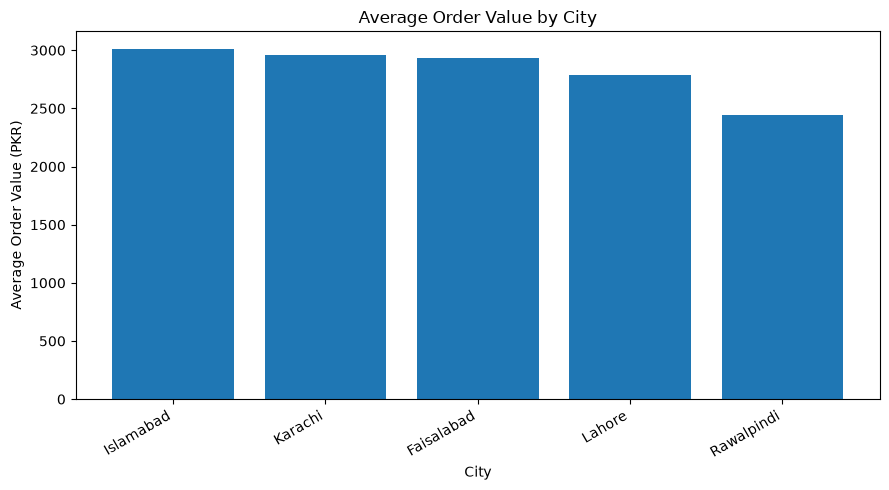

In [20]:
average_value_by_city = ecommerce.groupby("city")["order_value"].mean().sort_values(ascending=False)
display(average_value_by_city)

plt.figure(figsize=(9, 5))
plt.bar(average_value_by_city.index, average_value_by_city.values)
plt.title("Average Order Value by City")
plt.xlabel("City")
plt.ylabel("Average Order Value (PKR)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


## Dataset 2: Student Lifestyle & Study Habits

In [21]:
# Basic data check
print("Missing values in student data:")
display(students.isna().sum())


Missing values in student data:


student_id              0
gender                  0
study_hours             0
sleep_hours             0
screen_time             0
internet_usage          0
daily_transport_cost    0
dtype: int64

### Q1. What is the average number of study hours?

**Answer: 4.40 hours** (rounded to two decimal places).

In [22]:
average_study_hours = students["study_hours"].mean()
print(f"Average study hours: {average_study_hours:.2f} hours")


Average study hours: 4.40 hours


### Q2. Who sleeps more on average — males or females?

**Answer: Females**, averaging **6.80 hours**, compared with **6.39 hours** for males.

In [23]:
average_sleep_by_gender = students.groupby("gender")["sleep_hours"].mean()
display(average_sleep_by_gender)
print("Group with higher average sleep:", average_sleep_by_gender.idxmax())


gender
Female    6.796154
Male      6.389583
Name: sleep_hours, dtype: float64

Group with higher average sleep: Female


### Q3. Is there a relationship between screen time and sleep hours?

**Answer: There is a very weak positive relationship** in this dataset. The Pearson correlation is approximately **0.05**, which is so close to zero that it indicates almost no linear relationship.

Correlation between screen time and sleep hours: 0.052


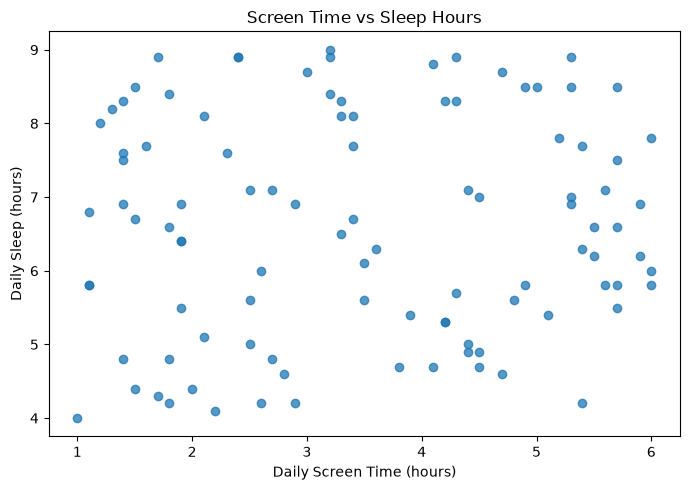

In [24]:
screen_sleep_correlation = students["screen_time"].corr(students["sleep_hours"])
print(f"Correlation between screen time and sleep hours: {screen_sleep_correlation:.3f}")

plt.figure(figsize=(7, 5))
plt.scatter(students["screen_time"], students["sleep_hours"], alpha=0.75)
plt.title("Screen Time vs Sleep Hours")
plt.xlabel("Daily Screen Time (hours)")
plt.ylabel("Daily Sleep (hours)")
plt.tight_layout()
plt.show()


### Q4. Draw a histogram of daily transport cost.

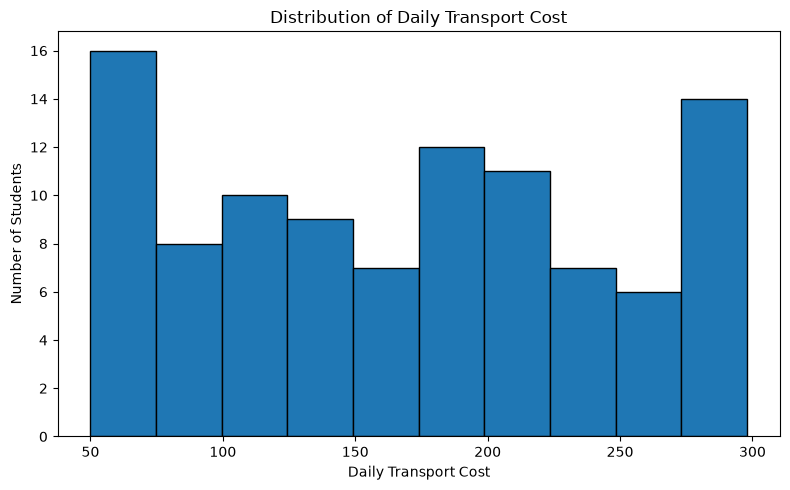

In [25]:
plt.figure(figsize=(8, 5))
plt.hist(students["daily_transport_cost"], bins=10, edgecolor="black")
plt.title("Distribution of Daily Transport Cost")
plt.xlabel("Daily Transport Cost")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()


### Q5. Compare average internet usage by gender.

**Answer: Males** have higher average internet usage: **6.00 hours**, compared with **5.32 hours** for females.

gender
Female    5.321154
Male      6.002083
Name: internet_usage, dtype: float64

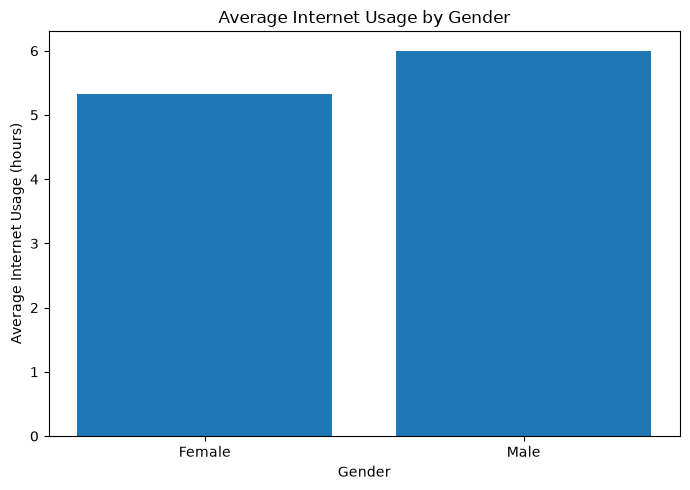

In [26]:
average_internet_by_gender = students.groupby("gender")["internet_usage"].mean()
display(average_internet_by_gender)

plt.figure(figsize=(7, 5))
plt.bar(average_internet_by_gender.index, average_internet_by_gender.values)
plt.title("Average Internet Usage by Gender")
plt.xlabel("Gender")
plt.ylabel("Average Internet Usage (hours)")
plt.tight_layout()
plt.show()


## Final Answers — Quick Summary

### Pakistani E-Commerce
1. Most popular product category: **Home Decor** (30 orders).
2. Average order value: **PKR 2,832.15**.
3. City with the most orders: **Karachi** (24 orders).
4. Most used payment method: **Cash on Delivery** (29 orders).
5. Bar chart: average order value by city is produced in the Q5 cell.

### Student Lifestyle & Study Habits
1. Average study time: **4.40 hours**.
2. Higher average sleep: **Females** (6.80 hours vs 6.39 hours).
3. Screen time vs sleep: **very weak positive correlation** (r = 0.052), effectively almost no linear relationship.
4. Histogram: daily transport cost distribution is produced in the Q4 cell.
5. Higher average internet usage: **Males** (6.00 hours vs 5.32 hours).

**Interpretation note:** A correlation close to zero means these data do not show a meaningful linear association; it does not prove that screen time can never affect sleep.